In [3]:
import json, gzip, pathlib
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

BASE = pathlib.Path('T7/final')
T = lambda s: pd.Timestamp(f'2026-10-24T{s}Z')

# vmagent buffer, with the process start time so the two boots can be told apart
rows = {}
with gzip.open(BASE / 'export_vmagent_pi.jsonl.gz', 'rt') as f:
    for line in f:
        d = json.loads(line)
        n = d['metric']['__name__']
        if n in ('vmagent_remotewrite_pending_data_bytes', 'process_start_time_seconds'):
            rows[n] = pd.Series(d['values'], index=pd.to_datetime(d['timestamps'], unit='ms', utc=True)).sort_index()
buf = pd.DataFrame({'kB': rows['vmagent_remotewrite_pending_data_bytes'] / 1e3})
buf['start'] = rows['process_start_time_seconds'].reindex(buf.index, method='nearest')

# After the power cut the Pi had no internet, so its clock ran 239 s slow until NTP
# synchronised at 12:22:53 UTC (from pi_uptime_seconds: apparent boot 11:52:15 before
# the sync, 11:56:14 after). Samples from the second boot taken before the sync are
# shifted forward by 239 s to real time.
OFFSET = pd.Timedelta(seconds=239)
second_boot = buf['start'] > buf['start'].min() + 3600
unsynced = second_boot & (buf.index < T('12:18:55'))
buf.index = buf.index.where(~unsynced, buf.index + OFFSET)
buf = buf.sort_index()

# events (UTC), real time
outage1   = (T('11:37:30'), T('11:43:40'))   # backhaul state down -> up
outage2   = (T('11:49:10'), T('12:22:35'))   # backhaul down, including the power cut
power_off = (T('11:54:34'), T('11:56:14'))   # last pre-cut sample -> boot
starting  = (T('11:56:14'), T('11:57:24'))   # boot -> first measurement
local_down= (T('11:57:24'), T('11:59:41'))   # Wi-Fi not yet connected
print(f'{len(buf)} buffer samples, {unsynced.sum()} shifted by 239 s')

3441 buffer samples, 101 shifted by 239 s


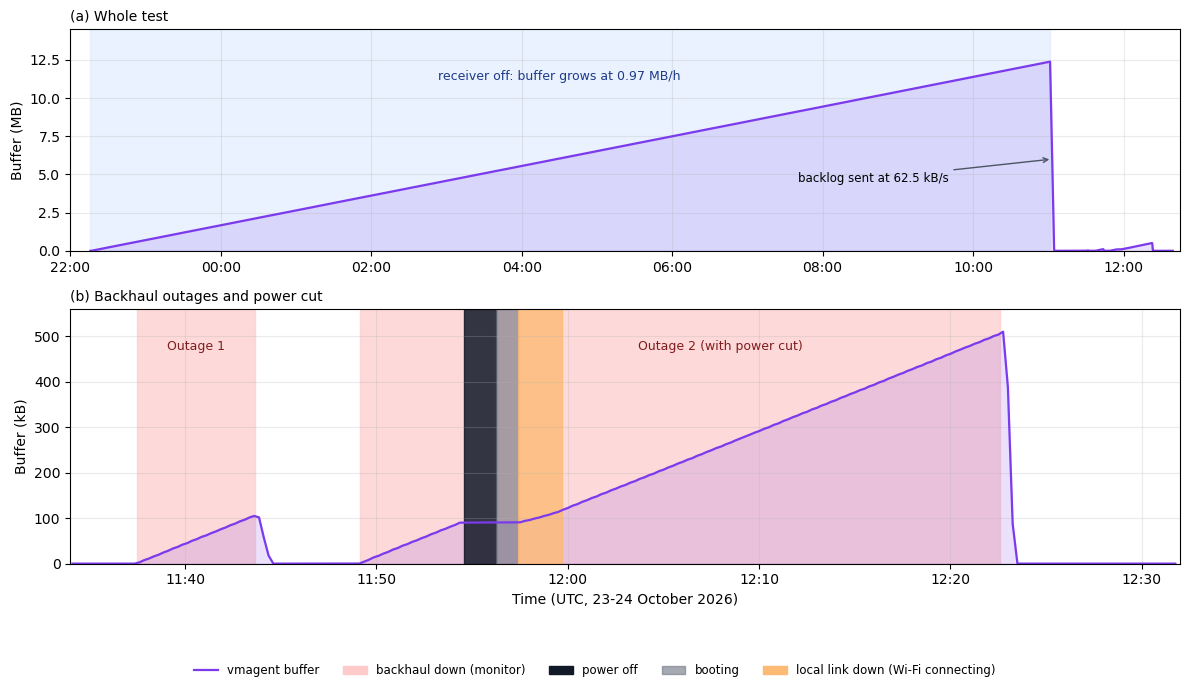

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.6), gridspec_kw={'height_ratios': [1, 1.15]})

# (a) whole run: overnight growth with the receiver off, then the backlog drain
ax1.plot(buf.index, buf['kB'] / 1e3, color='#7c3aed', lw=1.6)
ax1.fill_between(buf.index, buf['kB'] / 1e3, color='#7c3aed', alpha=0.15)
ax1.axvspan(pd.Timestamp('2026-10-23T22:16Z'), T('11:01:22'), color='#dbeafe', alpha=0.6, zorder=0)
ax1.text(pd.Timestamp('2026-10-24T04:30Z'), 11.2, 'receiver off: buffer grows at 0.97 MB/h', ha='center', fontsize=9, color='#1e3a8a')
ax1.annotate('backlog sent at 62.5 kB/s', xy=(T('11:03'), 6), xytext=(T('07:40'), 4.5),
             fontsize=8.5, arrowprops=dict(arrowstyle='->', color='#4b5563'))
ax1.set_ylabel('Buffer (MB)'); ax1.set_ylim(0, 14.5)
ax1.set_xlim(pd.Timestamp('2026-10-23T22:00Z'), T('12:45'))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC'))
ax1.set_title('(a) Whole test', fontsize=10, loc='left')

# (b) zoom: backhaul outages and the power cut
z = buf[T('11:34'):T('12:32')]
ax2.plot(z.index, z['kB'], color='#7c3aed', lw=1.6)
ax2.fill_between(z.index, z['kB'], color='#7c3aed', alpha=0.15)
for s in (outage1, outage2):
    ax2.axvspan(*s, color='#fecaca', alpha=0.7, zorder=0)
ax2.axvspan(*power_off, color='#111827', alpha=0.85, zorder=1)
ax2.axvspan(*starting, color='#6b7280', alpha=0.6, zorder=1)
ax2.axvspan(*local_down, color='#fdba74', alpha=0.8, zorder=1)
ax2.text(outage1[0] + (outage1[1]-outage1[0])/2, 470, 'Outage 1', ha='center', fontsize=9, color='#7f1d1d')
ax2.text(T('12:08'), 470, 'Outage 2 (with power cut)', ha='center', fontsize=9, color='#7f1d1d')
ax2.set_ylabel('Buffer (kB)'); ax2.set_ylim(0, 560)
ax2.set_xlim(T('11:34'), T('12:32'))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC'))
ax2.set_xlabel('Time (UTC, 23-24 October 2026)')
ax2.set_title('(b) Backhaul outages and power cut', fontsize=10, loc='left')
for ax in (ax1, ax2): ax.grid(True, alpha=0.25)

handles = [Line2D([0], [0], color='#7c3aed', lw=1.6, label='vmagent buffer'),
           mpatches.Patch(color='#fecaca', label='backhaul down (monitor)'),
           mpatches.Patch(color='#111827', label='power off'),
           mpatches.Patch(color='#6b7280', alpha=0.6, label='booting'),
           mpatches.Patch(color='#fdba74', label='local link down (Wi-Fi connecting)')]
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('t6_long_run.png', dpi=180, bbox_inches='tight')
plt.savefig('t6_long_run.pdf', bbox_inches='tight')
plt.show()

            Window  CPU mean (%)  CPU p95 (%)  Load (1 min)  Memory (%)  Temp mean (C)  Temp max (C)
      Idle (night)          0.58         0.80          0.07       16.15          57.00          64.5
Handling an outage          0.87         2.14          0.21       16.16          57.35          61.1


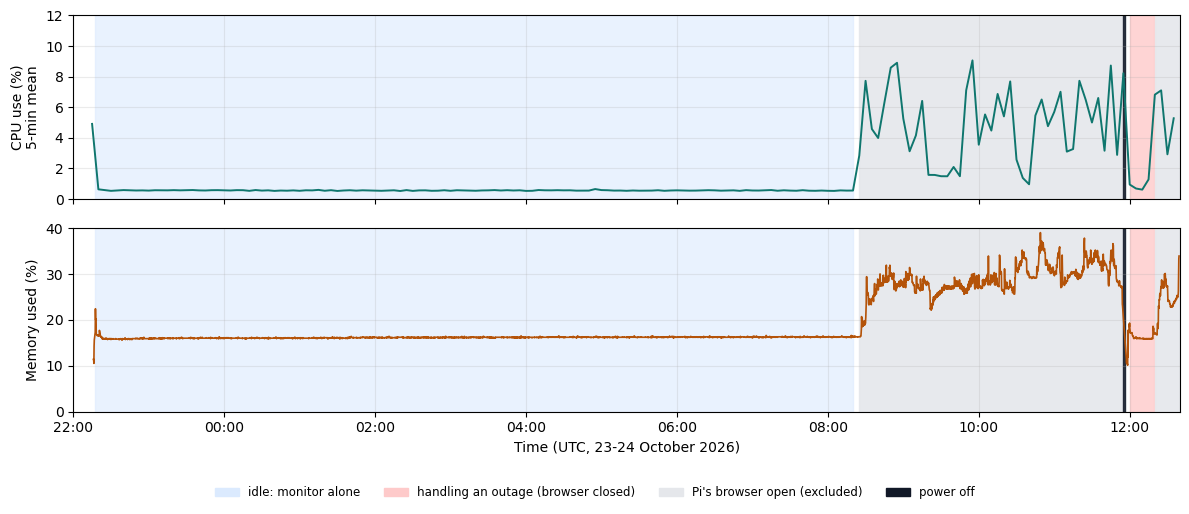

In [5]:
# Resources over the whole test. Memory use shows when the Pi's own browser was open
# (about 16 % without it, 25-34 % with it), so those periods are marked and left out.
R = {}
with gzip.open(BASE / 'export_pi5_pi.jsonl.gz', 'rt') as f:
    for line in f:
        d = json.loads(line)
        n = d['metric']['__name__']
        if n in ('pi_cpu_usage_pct', 'pi_memory_used_pct', 'pi_cpu_temp_celsius', 'pi_uptime_seconds', 'pi_load_avg') \
           and d['metric'].get('period', '1m') == '1m':
            R[n] = pd.Series(d['values'], index=pd.to_datetime(d['timestamps'], unit='ms', utc=True)).sort_index()
res = pd.DataFrame(R)
fix = (res.index >= T('11:53:20')) & (res.index < T('12:18:56')) & (res['pi_uptime_seconds'] < 20000)
res.index = res.index.where(~fix, res.index + OFFSET)          # same 239 s clock correction
res = res.sort_index()

idle    = (pd.Timestamp('2026-10-23T22:17Z'), T('08:20'))   # monitor alone, receiver off
working = (T('12:00'), T('12:19'))                          # backhaul down after the restart, browser closed
browser = [(T('08:25'), T('11:54')), (T('12:20'), T('12:40'))]

rows = []
for name, (a, b) in [('Idle (night)', idle), ('Handling an outage', working)]:
    w = res[a:b]
    rows.append({'Window': name, 'CPU mean (%)': w.pi_cpu_usage_pct.mean(), 'CPU p95 (%)': w.pi_cpu_usage_pct.quantile(.95),
                 'Load (1 min)': w.pi_load_avg.mean(), 'Memory (%)': w.pi_memory_used_pct.mean(),
                 'Temp mean (C)': w.pi_cpu_temp_celsius.mean(), 'Temp max (C)': w.pi_cpu_temp_celsius.max()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
cpu5 = res.pi_cpu_usage_pct.resample('5min').mean()
a1.plot(cpu5.index, cpu5, color='#0f766e', lw=1.4)
a2.plot(res.index, res.pi_memory_used_pct, color='#b45309', lw=1.2)
for ax in (a1, a2):
    ax.axvspan(*idle, color='#dbeafe', alpha=0.6, zorder=0)
    ax.axvspan(*working, color='#fecaca', alpha=0.8, zorder=0)
    for s in browser: ax.axvspan(*s, color='#e5e7eb', alpha=0.9, zorder=0)
    ax.axvspan(*power_off, color='#111827', alpha=0.85, zorder=1)
    ax.grid(True, alpha=0.25)
a1.set_ylabel('CPU use (%)\n5-min mean'); a1.set_ylim(0, 12)
a2.set_ylabel('Memory used (%)'); a2.set_ylim(0, 40)
a2.set_xlim(pd.Timestamp('2026-10-23T22:00Z'), T('12:40'))
a2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC'))
a2.set_xlabel('Time (UTC, 23-24 October 2026)')
handles = [mpatches.Patch(color='#dbeafe', label='idle: monitor alone'),
           mpatches.Patch(color='#fecaca', label='handling an outage (browser closed)'),
           mpatches.Patch(color='#e5e7eb', label="Pi's browser open (excluded)"),
           mpatches.Patch(color='#111827', label='power off')]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('t6_resources.png', dpi=180, bbox_inches='tight')
plt.savefig('t6_resources.pdf', bbox_inches='tight')
plt.show()